<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/%5BLab_7_SSL%5D_Detection_Part_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Lab 01 — Object Detection
## Dobble / Spot It!: YOLO11 vs. frozen DINOv1 + a detection head

**Course:** Deep Learning · **Environment:** Google Colab / Jupyter (GPU recommended) · **Recommended duration:** 90–120 minutes excluding lengthy model downloads.


### Learning objectives
1. Interpret YOLO-format bounding-box annotations and assess dataset split quality.
2. Fine-tune a pretrained YOLO detector and train a small head on **frozen DINOv1 spatial patch features**.
3. Understand the difference between a detection-pretrained system and a self-supervised feature backbone.
4. Evaluate both on an identical untouched test split using **mAP@50 and mAP@50:95** and visualize predictions.
5. Solve a simplified Dobble matching-symbol problem.

> **Experimental caution:** This is a teaching comparison of two transfer-learning workflows, **not** a controlled backbone benchmark. YOLO and DINO have different pretraining and model capacity.

**Before running:** `Runtime → Change runtime type → T4 GPU`. Export the **Dobble object detection** dataset from Roboflow as **YOLOv8 (PyTorch TXT)** ZIP. Run from the first cell to the last; do **not** reuse v1 cached features or trained checkpoints.

## Schedule
| Part | Topic | Target |
|---|---|---|
| 0 | Setup and raw dataset import | 10 min |
| 1 | Dataset audit and **new group-aware 80/20 split** | 15 min |
| 2 | Train YOLO11 nano | 20–30 min |
| 3 | Frozen DINOv1 patch features + trainable detector | 25–40 min |
| 4 | Joint mAP evaluation, visualization, discussion | 15–20 min |

**Ground truth:** one `.txt` per image, each row `class_id cx cy width height` with coordinates normalized to `[0,1]`. Multiple rows = multiple symbols in one picture.

## 0. Install dependencies and configure the runtime
- Use a Colab GPU when possible.
- Set all data-loader workers to **0** to avoid multiprocessing issues in notebook runtimes.
- We use the existing YOLO11n model family to match the original lab.

In [ ]:
%pip -q install ultralytics torchmetrics pycocotools pyyaml

In [ ]:
import os, gc, random, shutil, hashlib, math, zipfile
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.ops import batched_nms
from PIL import Image
from matplotlib.patches import Rectangle
from scipy.fft import dctn
import yaml
from tqdm.auto import tqdm
from ultralytics import YOLO
from torchmetrics.detection.mean_ap import MeanAveragePrecision

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:',torch.__version__,'| Device:',DEVICE)
if DEVICE.type!='cuda': print('GPU recommended for YOLO training and DINO feature extraction.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130 | Device: cuda


## 1. Import the **original** Roboflow YOLOv8 detection ZIP

Download [Dobble Cards Object Detection](https://universe.roboflow.com/aravind-ellapu/dobble-cards-object-detection) as **YOLOv8 (PyTorch TXT)**, not segmentation. Either upload the ZIP in Colab or set `ZIP_PATH` to a locally available file (e.g., in mounted Drive).

**Do not upload the lab output folder or an already-resplit dataset.** Always begin from the original Roboflow export so that the revised split is reproducible.

In [ ]:
# If the ZIP already exists on Colab/Drive, provide an absolute file path here.
# Otherwise keep None and select it using Colab's upload dialog.
ZIP_PATH=None  # e.g. '/content/drive/MyDrive/dobble-yolov8.zip'
RAW_ROOT=Path('/content/dobble_original_v2' if Path('/content').exists() else './dobble_original_v2')
RAW_ROOT.mkdir(parents=True,exist_ok=True)

if ZIP_PATH is None:
    try:
        from google.colab import files
        uploaded=files.upload()
        candidates=[Path(name) for name in uploaded if name.lower().endswith('.zip')]
        assert len(candidates)==1,'Upload exactly one YOLOv8 detection ZIP.'
        zip_path=candidates[0]
    except ModuleNotFoundError:
        zip_path=Path('dobble_yolov8.zip')
        assert zip_path.exists(),'Place dobble_yolov8.zip beside the notebook or provide ZIP_PATH.'
else:
    zip_path=Path(ZIP_PATH)
assert zip_path.exists(),f'ZIP not found: {zip_path}'

with zipfile.ZipFile(zip_path) as zf:
    zf.extractall(RAW_ROOT)
all_yamls=list(RAW_ROOT.rglob('data.yaml'))
assert len(all_yamls)==1,f'Expected exactly one data.yaml; found {len(all_yamls)}. Start with an empty RAW_ROOT or a single export.'
source_yaml=all_yamls[0]
source_dir=source_yaml.parent
raw_cfg=yaml.safe_load(source_yaml.read_text())
raw_names=raw_cfg['names']
raw_names=([raw_names.get(i,raw_names.get(str(i))) for i in range(len(raw_names))]
           if isinstance(raw_names,dict) else list(raw_names))
assert all(isinstance(name,str) for name in raw_names)
IMG_EXT={'.jpg','.jpeg','.png','.bmp','.webp'}
print('Source:',source_dir)
print('Raw classes:',len(raw_names),'| Examples:',raw_names[:12])

Saving Dobble Cards Object Detection.v2i.yolov8.zip to Dobble Cards Object Detection.v2i.yolov8.zip
Source: /content/dobble_original_v2
Raw classes: 39 | Examples: ['Baby bottle', 'Bomb', 'Cactus', 'Candle', 'Carrot', 'Cheese', 'Chess Knight', 'Clock', 'Dinosaur', 'Dog', 'Dolphin', 'Exclamation point']


## 2. **Training and validation**

We combine the exported `train` and `valid` image pools, then form a deterministic **80/20 train/validation split**. The original `test` images stay held out. The previous **900 train / 6 validation** split is **not reused**.


`DEV_POOL_CAP=1000` makes this classroom-friendly; set it to `None` to use all development images. `TEST_CAP=None` preserves the **entire original test set**. You may cap it for a brief demo, but report that it is then a fixed test subset.

In [ ]:
DEV_POOL_CAP=1000
TEST_CAP=None  # keep ALL original test images
VAL_FRACTION=0.20
NEAR_DUP_DISTANCE=2  # conservative pHash Hamming distance; 0 means identical pHash only
IGNORE_CLASS_NAMES={'dobble'}  # ignore a whole-card label if present; learn symbols only

allowed=[i for i,n in enumerate(raw_names) if n.strip().lower() not in IGNORE_CLASS_NAMES]
CLASS_NAMES=[raw_names[i] for i in allowed]
class_map={old:new for new,old in enumerate(allowed)}
NUM_CLASSES=len(CLASS_NAMES)
assert NUM_CLASSES>0
LAB_ROOT=Path('/content/dobble_lab_v2' if Path('/content').exists() else './dobble_lab_v2')
LAB_ROOT.mkdir(parents=True,exist_ok=True)

def split_dirs(split):
    candidates={'train':['train'],'val':['valid','val'],'test':['test']}[split]
    for folder in candidates:
        im=source_dir/folder/'images'; lb=source_dir/folder/'labels'
        if im.exists(): return im,lb
    raise FileNotFoundError(f'Missing {split} in {source_dir}')

def records_from(split):
    im_dir,lb_dir=split_dirs(split)
    ims=sorted(p for p in im_dir.iterdir() if p.suffix.lower() in IMG_EXT)
    out=[]
    for p in ims:
        out.append({'source_split':split,'image':p,
                    'label':lb_dir/(p.stem+'.txt')})
    return out

source_train=records_from('train')
source_val=records_from('val')
source_test=records_from('test')
print('Raw source counts:',{'train':len(source_train),'valid':len(source_val),'test':len(source_test)})
assert len(source_train)+len(source_val)>=200,'Not enough development data to make a reliable classroom split.'
assert len(source_test)>0,'Test set is missing; do not reuse development images as test.'

dev=source_train+source_val
rng=np.random.default_rng(SEED)
if DEV_POOL_CAP is not None and len(dev)>DEV_POOL_CAP:
    idx=rng.choice(len(dev),size=DEV_POOL_CAP,replace=False)
    dev=[dev[int(i)] for i in sorted(idx)]
if TEST_CAP is not None and len(source_test)>TEST_CAP:
    idx=np.random.default_rng(SEED+1).choice(len(source_test),TEST_CAP,replace=False)
    source_test=[source_test[int(i)] for i in sorted(idx)]

# SHA protects against exact duplicate test leakage; pHash catches close visual copies.
def sha256_file(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1<<20),b''): h.update(block)
    return h.hexdigest()

def perceptual_hash(path):
    # 64-bit pHash; no external image-hash dependency.
    with Image.open(path) as im:
        a=np.asarray(im.convert('L').resize((32,32),Image.Resampling.LANCZOS),dtype=np.float64)
    low=dctn(a,type=2,norm='ortho')[:8,:8]
    threshold=np.median(low.flatten()[1:])
    return sum((int(v>=threshold)<<i) for i,v in enumerate(low.flatten()))

for r in tqdm(dev+source_test,desc='Hashing images'):
    r['sha']=sha256_file(r['image'])
    r['phash']=perceptual_hash(r['image'])

test_hashes={r['sha'] for r in source_test}
test_phashes=[r['phash'] for r in source_test]
raw_dev_count=len(dev)
dev=[r for r in dev if r['sha'] not in test_hashes and
     all((r['phash']^t).bit_count()>NEAR_DUP_DISTANCE for t in test_phashes)]
print('Development images excluded due to (near-)duplicate test images:',raw_dev_count-len(dev))
assert len(dev)>=200,'Too few development images remain after test leakage filtering.'

Raw source counts: {'train': 3795, 'valid': 6, 'test': 91}


Hashing images:   0%|          | 0/1091 [00:00<?, ?it/s]

Development images excluded due to (near-)duplicate test images: 4


In [ ]:
# Group exact/near-duplicate development images so they never cross train/val.
parent=list(range(len(dev)))
def root(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i

def unite(a,b):
    a,b=root(a),root(b)
    if a!=b: parent[max(a,b)]=min(a,b)

for i in range(len(dev)):
    for j in range(i):
        if (dev[i]['phash']^dev[j]['phash']).bit_count()<=NEAR_DUP_DISTANCE:
            unite(i,j)
groups=defaultdict(list)
for i in range(len(dev)): groups[root(i)].append(i)
groups=list(groups.values())
print('Development images:',len(dev),'| Near-duplicate groups:',len(groups),
      '| Largest group:',max(len(g) for g in groups))

# Keep each class represented in training whenever possible.
def class_ids(r):
    if not r['label'].exists(): return set()
    ids=set()
    for line in r['label'].read_text().splitlines():
        v=line.split()
        if len(v)==5:
            c=int(float(v[0]))
            if c in class_map: ids.add(class_map[c])
    return ids

group_classes=[set().union(*(class_ids(dev[i]) for i in g)) for g in groups]
remaining=Counter(c for cats in group_classes for c in cats)
order=np.random.default_rng(SEED).permutation(len(groups))
target_val=round(VAL_FRACTION*len(dev))
val_g=set(); val_count=0
for gi in order:
    g=groups[int(gi)]; cats=group_classes[int(gi)]
    if val_count>=target_val: break
    if val_count+len(g)>target_val+max(2,max(len(z) for z in groups)): continue
    if any(remaining[c]<=1 for c in cats): continue
    val_g.add(int(gi)); val_count+=len(g)
    for c in cats: remaining[c]-=1

val_indices={i for gi,g in enumerate(groups) if gi in val_g for i in g}
new_train=[r for i,r in enumerate(dev) if i not in val_indices]
new_val=[r for i,r in enumerate(dev) if i in val_indices]
assert len(new_train)>len(new_val)>=max(40,int(0.10*len(dev))),(
    f'Validation is too small ({len(new_val)}); inspect duplicate groups.')
print('Rebuilt split:',{'train':len(new_train),'val':len(new_val),'test':len(source_test)})

# Remap source YOLO class IDs to our contiguous symbol IDs. Build ONE export for both models.
def remap_label(path):
    output=[]
    if not path.exists(): return output
    for line in path.read_text().splitlines():
        v=line.split()
        if len(v)!=5: continue
        old=int(float(v[0]))
        if old not in class_map: continue
        x,y,w,h=map(float,v[1:])
        if not np.isfinite([x,y,w,h]).all(): continue
        if not(0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1): continue
        output.append(f'{class_map[old]} {x:.8f} {y:.8f} {w:.8f} {h:.8f}')
    return output

manifest=[]
for split,records in [('train',new_train),('val',new_val),('test',source_test)]:
    image_dir=LAB_ROOT/split/'images'
    label_dir=LAB_ROOT/split/'labels'
    # Only delete the generated output of this version; never the source export.
    if image_dir.exists(): shutil.rmtree(image_dir)
    if label_dir.exists(): shutil.rmtree(label_dir)
    image_dir.mkdir(parents=True);label_dir.mkdir(parents=True)
    for i,r in enumerate(records):
        stem=f'{split}_{i:05d}'
        dest=image_dir/(stem+r['image'].suffix.lower())
        shutil.copy2(r['image'],dest)
        new_label=label_dir/(stem+'.txt')
        lines=remap_label(r['label'])
        new_label.write_text('\n'.join(lines)+('\n' if lines else ''))
        manifest.append(dict(split=split,image=str(dest),label=str(new_label),
                             source_split=r['source_split'],source_image=str(r['image']),
                             sha256=r['sha'],objects=len(lines)))
manifest=pd.DataFrame(manifest)
manifest.to_csv(LAB_ROOT/'split_manifest.csv',index=False)
LAB_YAML=LAB_ROOT/'data.yaml'
LAB_YAML.write_text(yaml.safe_dump(dict(path=str(LAB_ROOT.resolve()),
    train='train/images',val='val/images',test='test/images',
    names=CLASS_NAMES,nc=NUM_CLASSES),sort_keys=False))
print(manifest.groupby('split').agg(images=('image','size'),objects=('objects','sum')))
print('Class count:',NUM_CLASSES,'| YOLO YAML:',LAB_YAML)

Development images: 996 | Near-duplicate groups: 946 | Largest group: 3
Rebuilt split: {'train': 797, 'val': 199, 'test': 91}
       images  objects
split                 
test       91      696
train     797     5718
val       199     1425
Class count: 39 | YOLO YAML: /content/dobble_lab_v2/data.yaml


### Sanity checks: labels, class coverage, and duplicate leakage
We must see **far more than six validation images**. These checks run **before** training either model. We use the final `split_manifest.csv` to audit which file is in which partition.

train: images=797, objects=5718, classes=39
val: images=199, objects=1425, classes=39
test: images=91, objects=696, classes=36
Classes in validation missing from training: []
Classes in test missing from training: []
PASS: no exact image hashes are shared across train/val/test.


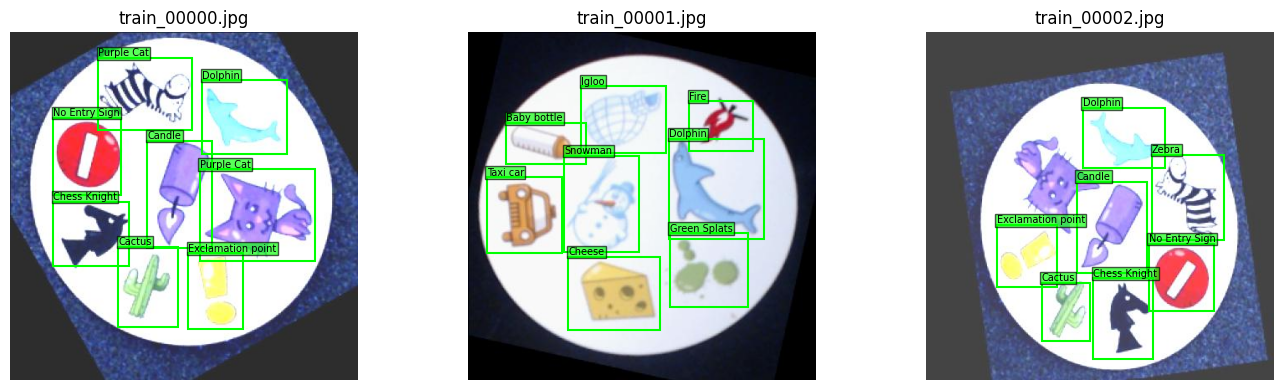

In [ ]:
def load_yolo_targets(path):
    lines=[]
    if Path(path).exists():
        for line in Path(path).read_text().splitlines():
            vals=line.split()
            if len(vals)==5:
                lines.append([float(v) for v in vals])
    return torch.tensor(lines,dtype=torch.float32).reshape(-1,5)

def audit(split):
    subset=manifest[manifest.split==split]
    freq=Counter()
    for p in subset.label:
        for row in load_yolo_targets(p): freq[int(row[0])]+=1
    print(f'{split}: images={len(subset)}, objects={sum(freq.values())}, classes={len(freq)}')
    return freq

train_counts=audit('train');val_counts=audit('val');test_counts=audit('test')
print('Classes in validation missing from training:',sorted(set(val_counts)-set(train_counts)))
print('Classes in test missing from training:',sorted(set(test_counts)-set(train_counts)))
assert len(manifest[manifest.split=='val'])>=40,'Validation set still too small!'
# Pairwise exact cross-split check using source hashes.
hashes={s:set(manifest.loc[manifest.split==s,'sha256']) for s in ('train','val','test')}
assert all(not(hashes[a]&hashes[b]) for a,b in [('train','val'),('train','test'),('val','test')])
print('PASS: no exact image hashes are shared across train/val/test.')

def show_boxes(img_path, rows, ax=None, title=None):
    if ax is None: _,ax=plt.subplots(figsize=(5,5))
    image=Image.open(img_path).convert('RGB'); W,H=image.size
    ax.imshow(image)
    for c,x,y,w,h in rows.tolist():
        ax.add_patch(Rectangle(((x-w/2)*W,(y-h/2)*H),w*W,h*H,
                       fill=False,edgecolor='lime',linewidth=1.5))
        ax.text((x-w/2)*W,max(0,(y-h/2)*H-2),CLASS_NAMES[int(c)],fontsize=7,
                bbox=dict(facecolor='lime',alpha=.65,pad=1))
    ax.set_title(title or Path(img_path).name);ax.axis('off')
    return ax

examples=manifest[manifest.split=='train'].head(3)
fig,axs=plt.subplots(1,len(examples),figsize=(14,4))
for ax,(_,r) in zip(axs,examples.iterrows()):
    show_boxes(r.image,load_yolo_targets(r.label),ax)
plt.tight_layout();plt.show()

## 3. Experiment A — **Train YOLO11**

We **start from the original pretrained** `yolo11n.pt`, not the `best.pt` created with the six-image validation set. YOLO trains on the `train` folder and selects its checkpoint using the new `val` folder; do **not** evaluate on test until both training pipelines finish.

This example uses a classroom budget of 15 epochs. Increase to 30–50 outside class for stronger Dobble symbol detection. `workers=0` avoids notebook multiprocessing queue issues. We disable mosaic augmentation to make the training images easier to compare with cached DINO feature training (this is still not a strictly controlled baseline).

In [ ]:
YOLO_EPOCHS=15
YOLO_IMGSZ=320
model=YOLO('yolo11n.pt')  # fresh pretrained detector; never load v1 best.pt
model.train(
    data=str(LAB_YAML),epochs=YOLO_EPOCHS,imgsz=YOLO_IMGSZ,batch=16,
    device=0 if DEVICE.type=='cuda' else 'cpu',workers=0,
    seed=SEED,project=str(LAB_ROOT/'runs'),name='yolo_corrected',
    exist_ok=True,patience=8,mosaic=0.0,mixup=0.0,
    plots=True,verbose=False
)
YOLO_BEST=Path(model.trainer.save_dir)/'weights'/'best.pt'
assert YOLO_BEST.exists(),f'YOLO checkpoint missing: {YOLO_BEST}'
yolo=YOLO(str(YOLO_BEST))
print('Reloaded YOLO best checkpoint:',YOLO_BEST)
# Record split manifest and training settings for reproducibility.
print('Training images:',len(manifest[manifest.split=='train']))
print('Validation images:',len(manifest[manifest.split=='val']))

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dobble_lab_v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo_corrected, nbs=64, nms=None, opset=None, optimize=Fa

### YOLO quick validation visualization (not final test scoring)
Compare the predicted symbol boxes against annotations. Do not tune any hyperparameters on the **test** set.

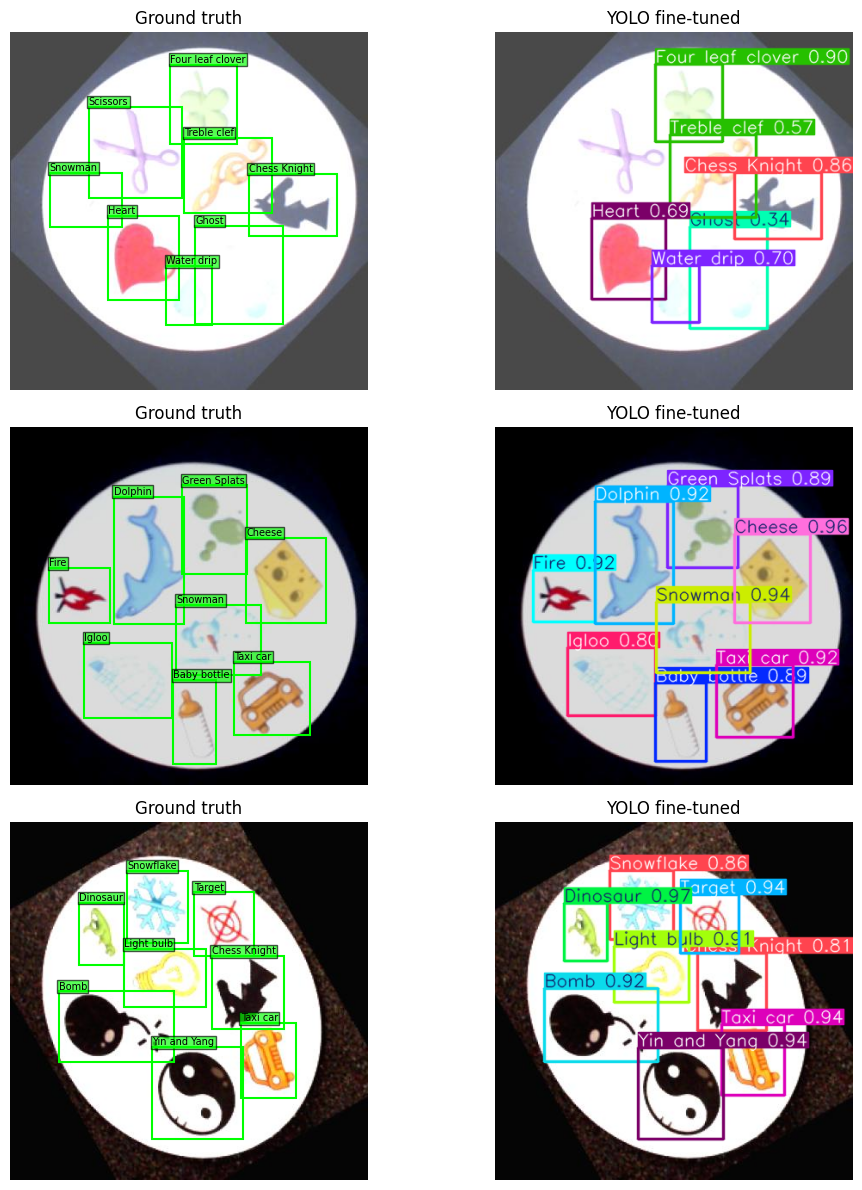

In [ ]:
val_examples=manifest[manifest.split=='val'].head(3)
fig,axs=plt.subplots(len(val_examples),2,figsize=(11,4*len(val_examples)),squeeze=False)
for i,(_,r) in enumerate(val_examples.iterrows()):
    show_boxes(r.image,load_yolo_targets(r.label),axs[i,0],'Ground truth')
    pred=yolo.predict(r.image,imgsz=YOLO_IMGSZ,conf=0.15,verbose=False)[0]
    axs[i,1].imshow(pred.plot()[...,::-1]);axs[i,1].set_title('YOLO fine-tuned');axs[i,1].axis('off')
plt.tight_layout();plt.show()

## 4. Experiment B — **Extract DINOv1 features**

DINOv1 ViT-S/16 is self-supervised: it has **not** been trained to output bounding boxes. Extract its **196 spatial patch tokens**, reshaped to `384 × 14 × 14`, and freeze the backbone. The new train/val/test directories drive fresh feature caches, so features can never silently come from the old split.

The model head below predicts objectness, symbol class, and bounding box per grid cell. Your earlier audit had **3 collisions in 6,421 objects (0.05%)**, so grid collisions are not the main issue we should optimize before fixing validation.

In [ ]:
DINO_SIZE=224
preprocess=T.Compose([
    T.Resize((DINO_SIZE,DINO_SIZE)),T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class DobbleImages(Dataset):
    def __init__(self,split):
        self.rows=manifest[manifest.split==split].reset_index(drop=True)
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        row=self.rows.iloc[i]
        with Image.open(row.image) as im: x=preprocess(im.convert('RGB'))
        return x,load_yolo_targets(row.label),row.image

def collate_images(items):
    return (torch.stack([x for x,_,_ in items]),
            [y for _,y,_ in items],[p for _,_,p in items])

image_loaders={s:DataLoader(DobbleImages(s),batch_size=16,shuffle=False,
                          num_workers=0,pin_memory=False,collate_fn=collate_images)
               for s in ('train','val','test')}

backbone=torch.hub.load('facebookresearch/dino:main','dino_vits16',pretrained=True).to(DEVICE).eval()
for p in backbone.parameters(): p.requires_grad_(False)
print('Frozen DINO backbone; trainable parameters:',sum(p.numel() for p in backbone.parameters() if p.requires_grad))

Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall16_pretrain/dino_deitsmall16_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall16_pretrain.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 316MB/s]


Frozen DINO backbone; trainable parameters: 0


In [ ]:
@torch.inference_mode()
def dino_patch_features(images):
    tokens=backbone.get_intermediate_layers(images.to(DEVICE),n=1)[0]
    patch=tokens[:,1:,:]  # discard CLS: need spatial positions for detection
    B,N,C=patch.shape
    S=math.isqrt(N)
    assert S*S==N and C==384,(N,C)
    return patch.transpose(1,2).reshape(B,C,S,S)

feature_sets={}
for split,loader in image_loaders.items():
    chunks,targets,paths=[],[],[]
    for imgs,labels,batch_paths in tqdm(loader,desc=f'New DINO features: {split}'):
        chunks.append(dino_patch_features(imgs).cpu().half())
        targets.extend(labels);paths.extend(batch_paths)
    feature_sets[split]=(torch.cat(chunks,dim=0),targets,paths)
    print(split,feature_sets[split][0].shape,'images')

# Double-check DINO's cached paths match the exact YOLO split manifest.
for split in ('train','val','test'):
    assert feature_sets[split][2]==manifest[manifest.split==split].image.tolist()
GRID=feature_sets['train'][0].shape[-1]
assert GRID==14
print('PASS: YOLO/DINO sample identities and order agree for every split.')

New DINO features: train:   0%|          | 0/50 [00:00<?, ?it/s]

train torch.Size([797, 384, 14, 14]) images


New DINO features: val:   0%|          | 0/13 [00:00<?, ?it/s]

val torch.Size([199, 384, 14, 14]) images


New DINO features: test:   0%|          | 0/6 [00:00<?, ?it/s]

test torch.Size([91, 384, 14, 14]) images
PASS: YOLO/DINO sample identities and order agree for every split.


## 5. Train a new DINOv1 multi-object detection head

**Only the head is trainable.** A cell containing an object center predicts that symbol's class and bounding box. Because this is a single-box-per-cell design, we audit collisions; the earlier observed rate was low. We use a moderate learning rate, weight decay, and validation-based early stopping. Unlike YOLO, this simple head has **no multiscale features**.

**Student exercise:** Why is `CLS` alone not sufficient for this localization task?

In [ ]:
class GridDetectionHead(nn.Module):
    def __init__(self,in_ch,classes):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Conv2d(in_ch,128,3,padding=1),
            nn.GroupNorm(8,128),nn.GELU(),nn.Dropout2d(0.20),
            nn.Conv2d(128,1+classes+4,1)
        )
    def forward(self,x): return self.layers(x.float())

head=GridDetectionHead(384,NUM_CLASSES).to(DEVICE)
optimizer=torch.optim.AdamW(head.parameters(),lr=3e-4,weight_decay=1e-2)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=2)

class CachedDetection(Dataset):
    def __init__(self,split): self.features,self.targets,self.paths=feature_sets[split]
    def __len__(self): return len(self.targets)
    def __getitem__(self,i): return self.features[i].float(),self.targets[i]

def collate_cached(items):
    return torch.stack([f for f,_ in items]),[t for _,t in items]

cached_loaders={s:DataLoader(CachedDetection(s),batch_size=32,shuffle=(s=='train'),
                            num_workers=0,pin_memory=False,collate_fn=collate_cached)
                for s in ('train','val')}

def make_grid_targets(targets,S,device):
    B=len(targets)
    obj=torch.zeros(B,S,S,device=device)
    cls=torch.zeros(B,S,S,dtype=torch.long,device=device)
    boxes=torch.zeros(B,S,S,4,device=device)
    collisions=0
    for b,rows in enumerate(targets):
        for c,cx,cy,w,h in rows.tolist():
            gx=min(S-1,max(0,int(cx*S)));gy=min(S-1,max(0,int(cy*S)))
            if obj[b,gy,gx].item()==1:
                collisions+=1;continue
            obj[b,gy,gx]=1;cls[b,gy,gx]=int(c)
            boxes[b,gy,gx]=torch.tensor([cx*S-gx,cy*S-gy,w,h],device=device)
    return obj,cls,boxes,collisions

def detection_loss(pred,targets):
    B,_,S,_=pred.shape
    obj,cls,boxes,collisions=make_grid_targets(targets,S,pred.device)
    obj_logit=pred[:,0]
    cls_logits=pred[:,1:1+NUM_CLASSES].permute(0,2,3,1)
    box_raw=pred[:,1+NUM_CLASSES:].permute(0,2,3,1)
    pos=obj.bool()
    obj_loss=F.binary_cross_entropy_with_logits(obj_logit,obj,
                         pos_weight=torch.tensor(12.,device=pred.device))
    if pos.any():
        cls_loss=F.cross_entropy(cls_logits[pos],cls[pos])
        box_loss=F.smooth_l1_loss(box_raw[pos].sigmoid(),boxes[pos])
    else:
        cls_loss=pred.sum()*0.
        box_loss=pred.sum()*0.
    return obj_loss+cls_loss+5*box_loss,(obj_loss.item(),cls_loss.item(),box_loss.item(),collisions)

# Smoke test before long training.
features,targets=next(iter(cached_loaders['train']))
pred=head(features.to(DEVICE));loss,parts=detection_loss(pred,targets)
optimizer.zero_grad(set_to_none=True);loss.backward()
optimizer.zero_grad(set_to_none=True)  # diagnostic only; begin training from fresh weights
print('Single forward/backward smoke test:',float(loss.item()),'| objectness, class, box, collisions:',parts)

Single forward/backward smoke test: 5.01591157913208 | objectness, class, box, collisions: (1.0376454591751099, 3.7486164569854736, 0.04592990502715111, 0)


Epoch 01 | train 2.879 | val 1.630 | obj 0.464 cls 1.071 box 0.019 | collisions 2 | lr 0.0003
Epoch 02 | train 1.140 | val 0.905 | obj 0.378 cls 0.449 box 0.016 | collisions 2 | lr 0.0003
Epoch 03 | train 0.705 | val 0.675 | obj 0.315 cls 0.293 box 0.013 | collisions 2 | lr 0.0003
Epoch 04 | train 0.534 | val 0.560 | obj 0.278 cls 0.222 box 0.012 | collisions 2 | lr 0.0003
Epoch 05 | train 0.440 | val 0.501 | obj 0.252 cls 0.193 box 0.011 | collisions 2 | lr 0.0003
Epoch 06 | train 0.375 | val 0.453 | obj 0.235 cls 0.165 box 0.011 | collisions 2 | lr 0.0003
Epoch 07 | train 0.325 | val 0.425 | obj 0.218 cls 0.155 box 0.010 | collisions 2 | lr 0.0003
Epoch 08 | train 0.296 | val 0.405 | obj 0.216 cls 0.141 box 0.010 | collisions 2 | lr 0.0003
Epoch 09 | train 0.265 | val 0.377 | obj 0.202 cls 0.130 box 0.009 | collisions 2 | lr 0.0003
Epoch 10 | train 0.242 | val 0.363 | obj 0.196 cls 0.121 box 0.009 | collisions 2 | lr 0.0003
Epoch 11 | train 0.225 | val 0.358 | obj 0.192 cls 0.122 box

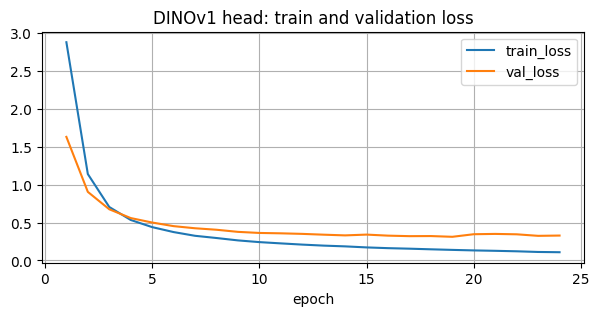

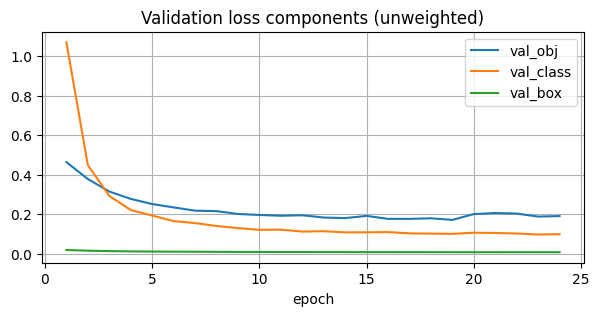

In [ ]:
HEAD_EPOCHS=25
EARLY_STOP=5
best_val=float('inf');best_state=None;wait=0;history=[]
for epoch in range(1,HEAD_EPOCHS+1):
    head.train();tr_parts=[];train_collisions=0
    for feats,targets in cached_loaders['train']:
        pred=head(feats.to(DEVICE))
        loss,parts=detection_loss(pred,targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward();nn.utils.clip_grad_norm_(head.parameters(),max_norm=5.0)
        optimizer.step()
        tr_parts.append(loss.item());train_collisions+=parts[3]

    head.eval();val_parts=[];val_components=[]
    with torch.no_grad():
        for feats,targets in cached_loaders['val']:
            loss,parts=detection_loss(head(feats.to(DEVICE)),targets)
            val_parts.append(loss.item());val_components.append(parts[:3])
    train_loss=float(np.mean(tr_parts));val_loss=float(np.mean(val_parts))
    val_obj,val_cls,val_box=np.array(val_components).mean(axis=0)
    history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
                    'val_obj':val_obj,'val_class':val_cls,'val_box':val_box})
    scheduler.step(val_loss)
    if val_loss<best_val-1e-4:
        best_val=val_loss;wait=0
        best_state={k:v.detach().cpu().clone() for k,v in head.state_dict().items()}
    else:
        wait+=1
    print(f'Epoch {epoch:02d} | train {train_loss:.3f} | val {val_loss:.3f} | '
          f'obj {val_obj:.3f} cls {val_cls:.3f} box {val_box:.3f} | '
          f'collisions {train_collisions} | lr {optimizer.param_groups[0]["lr"]:.5g}')
    if wait>=EARLY_STOP:
        print('Early stopping.');break
assert best_state is not None
head.load_state_dict(best_state)
HEAD_PATH=LAB_ROOT/'dino_detection_head_v2.pt'
torch.save({'state_dict':head.state_dict(),'class_names':CLASS_NAMES,'seed':SEED},HEAD_PATH)
print('Saved head:',HEAD_PATH)

hist=pd.DataFrame(history).set_index('epoch')
hist[['train_loss','val_loss']].plot(figsize=(7,3),grid=True,title='DINOv1 head: train and validation loss')
plt.show()
hist[['val_obj','val_class','val_box']].plot(figsize=(7,3),grid=True,title='Validation loss components (unweighted)')
plt.show()

## 6. Decode detections and calculate final metrics on the **same untouched test images**

We compute the standard detection mAP using `torchmetrics` for **both** models, using the same ground-truth test annotations and same image list. The raw detection box formats are converted into normalized `xyxy` coordinates. A confidence threshold of 0.001 avoids discarding most predictions before AP computation.

**Important:** Only evaluate the test split after training/checkpoint selection is complete. Do not tune either detector on test scores.

In [ ]:
@torch.no_grad()
def decode_grid(pred,threshold=0.001,nms_iou=0.5,max_det=100):
    B,_,S,_=pred.shape
    out=[]
    for i in range(B):
        p=pred[i]
        obj=p[0].sigmoid()
        probs=p[1:1+NUM_CLASSES].softmax(dim=0)
        cls_scores,labels=probs.max(dim=0)
        scores=(obj*cls_scores).reshape(-1)
        b=p[1+NUM_CLASSES:].sigmoid()
        yy,xx=torch.meshgrid(torch.arange(S,device=p.device),
                             torch.arange(S,device=p.device),indexing='ij')
        cx=(xx+b[0])/S;cy=(yy+b[1])/S
        w=b[2];h=b[3]
        boxes=torch.stack([cx-w/2,cy-h/2,cx+w/2,cy+h/2],dim=-1).reshape(-1,4).clamp(0,1)
        labels=labels.reshape(-1)
        keep=(scores>=threshold)&((boxes[:,2]-boxes[:,0])>0)&((boxes[:,3]-boxes[:,1])>0)
        scores=scores[keep];labels=labels[keep];boxes=boxes[keep]
        if len(scores):
            selected=batched_nms(boxes,scores,labels,nms_iou)[:max_det]
            scores=scores[selected];labels=labels[selected];boxes=boxes[selected]
        out.append({'boxes':boxes.cpu(),'scores':scores.cpu(),'labels':labels.cpu().long()})
    return out

def to_map_target(rows):
    if len(rows)==0:
        return {'boxes':torch.empty(0,4,dtype=torch.float32),
                'labels':torch.empty(0,dtype=torch.long)}
    c,cx,cy,w,h=rows.unbind(dim=1)
    boxes=torch.stack([cx-w/2,cy-h/2,cx+w/2,cy+h/2],dim=1).clamp(0,1)
    return {'boxes':boxes.float(),'labels':c.long()}

f_test,t_test,test_paths=feature_sets['test']
head.eval();dino_preds=[]
with torch.no_grad():
    for j in tqdm(range(0,len(f_test),32),desc='DINO test'):
        dino_preds.extend(decode_grid(head(f_test[j:j+32].to(DEVICE))))

yolo_preds=[]
for j in tqdm(range(0,len(test_paths),16),desc='YOLO test'):
    results=yolo.predict(test_paths[j:j+16],imgsz=YOLO_IMGSZ,conf=0.001,
                         iou=0.5,max_det=100,verbose=False)
    for r in results:
        H,W=r.orig_shape
        scale=torch.tensor([W,H,W,H],dtype=torch.float32)
        yolo_preds.append({'boxes':r.boxes.xyxy.detach().cpu()/scale,
                           'scores':r.boxes.conf.detach().cpu(),
                           'labels':r.boxes.cls.detach().cpu().long()})
assert len(test_paths)==len(yolo_preds)==len(dino_preds)==len(t_test)
targets=[to_map_target(x) for x in t_test]

metric_yolo=MeanAveragePrecision(box_format='xyxy',iou_type='bbox')
metric_dino=MeanAveragePrecision(box_format='xyxy',iou_type='bbox')
metric_yolo.update(yolo_preds,targets)
metric_dino.update(dino_preds,targets)
yolo_scores=metric_yolo.compute();dino_scores=metric_dino.compute()
comparison=pd.DataFrame([
  {'Model':'YOLO11n fine-tuned','mAP@50':float(yolo_scores['map_50']),
   'mAP@50:95':float(yolo_scores['map'])},
  {'Model':'Frozen DINOv1 + grid head','mAP@50':float(dino_scores['map_50']),
   'mAP@50:95':float(dino_scores['map'])}
]).set_index('Model')
display(comparison.round(4))
comparison.to_csv(LAB_ROOT/'final_detection_comparison.csv')

DINO test:   0%|          | 0/3 [00:00<?, ?it/s]

YOLO test:   0%|          | 0/6 [00:00<?, ?it/s]

,mAP@50,mAP@50:95
Model,,
YOLO11n fine-tuned,0.981,0.7869
Frozen DINOv1 + grid head,0.907,0.4029


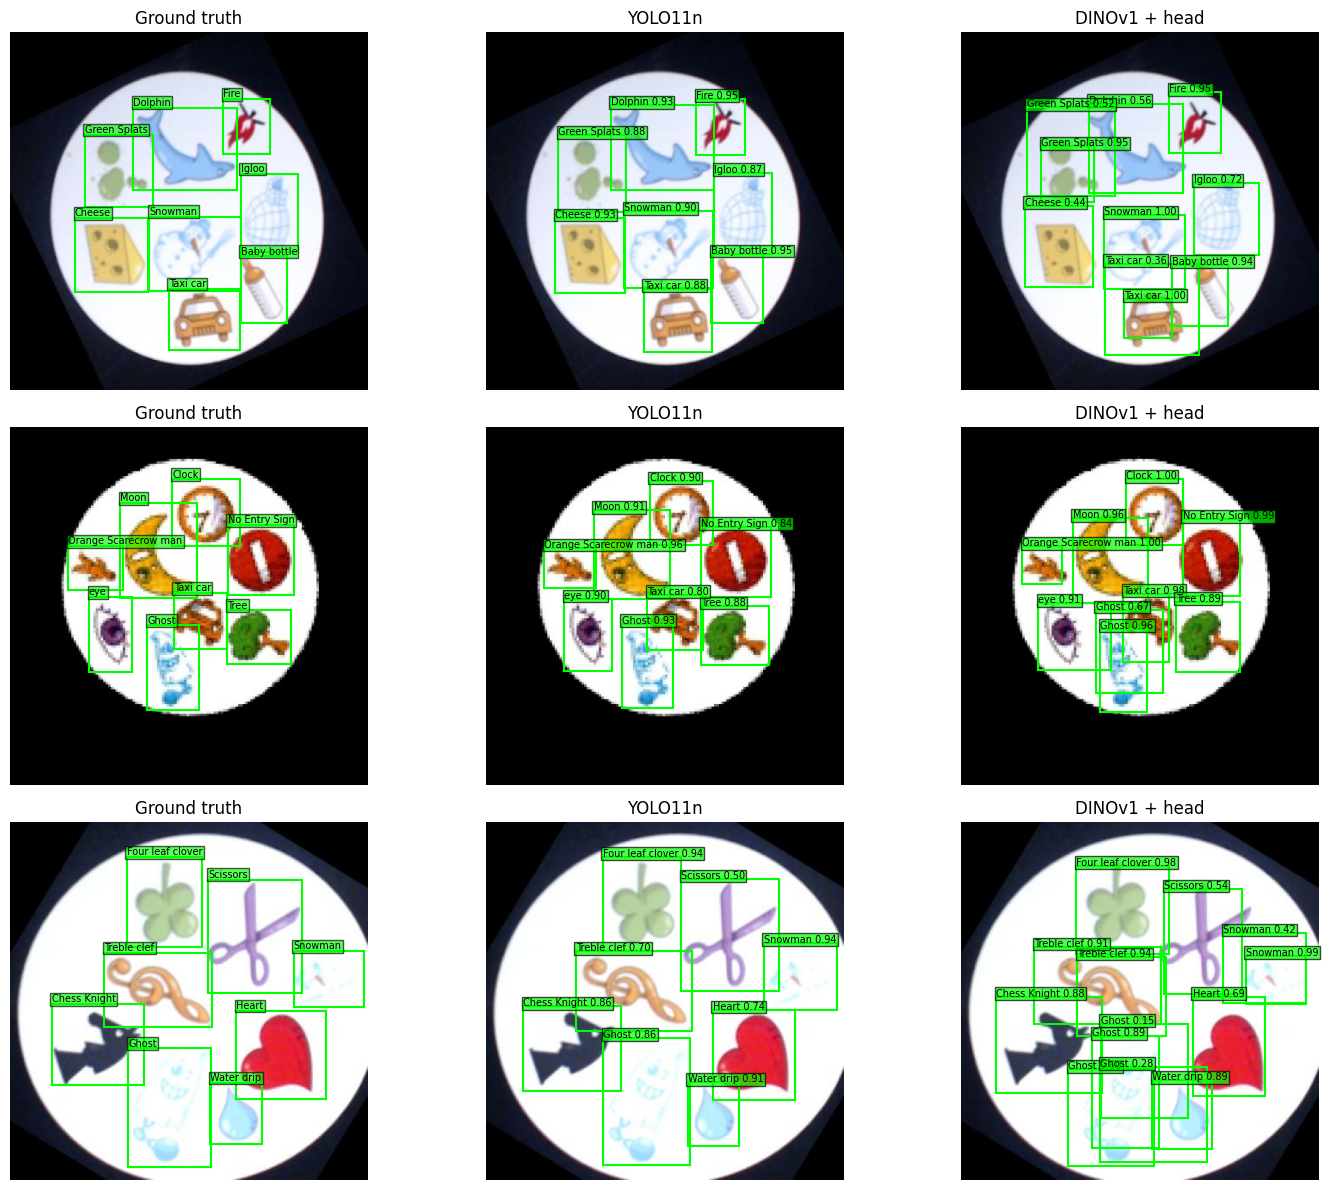

In [ ]:
# Compare real held-out predictions, side by side, using each model's detections.
def draw_pred(ax,img_path,pred,title,threshold=0.15):
    image=Image.open(img_path).convert('RGB');W,H=image.size
    ax.imshow(image)
    for box,score,label in zip(pred['boxes'],pred['scores'],pred['labels']):
        if float(score)<threshold: continue
        x1,y1,x2,y2=box.tolist()
        ax.add_patch(Rectangle((x1*W,y1*H),(x2-x1)*W,(y2-y1)*H,
                  fill=False,edgecolor='lime',linewidth=1.5))
        ax.text(x1*W,y1*H,f'{CLASS_NAMES[int(label)]} {float(score):.2f}',fontsize=7,
                bbox=dict(facecolor='lime',alpha=.7,pad=1))
    ax.set_title(title);ax.axis('off')

indices=list(range(min(3,len(test_paths))))
fig,axs=plt.subplots(len(indices),3,figsize=(15,4*len(indices)),squeeze=False)
for row,i in enumerate(indices):
    show_boxes(test_paths[i],t_test[i],axs[row,0],'Ground truth')
    draw_pred(axs[row,1],test_paths[i],yolo_preds[i],'YOLO11n')
    draw_pred(axs[row,2],test_paths[i],dino_preds[i],'DINOv1 + head')
plt.tight_layout();plt.show()

## 7. Dobble matching-symbol mini-project

A pair of valid Dobble cards shares one symbol. Using the detector's predicted **class labels**, find the most confident common class. This is a demonstration; the two sample images may not be a valid card pair, and multi-card images should be cropped first.

**Student exercise:** Compare the matching-symbol answer with YOLO and DINO predictions, and explain when matching fails.

Predicted shared symbol: Taxi car | confidences: 0.884 0.799


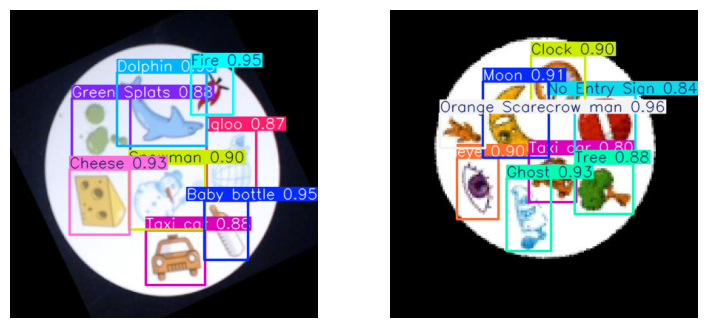

In [ ]:
# Choose two images showing individual cards, or replace with your own cropped card paths.
CARD_A=test_paths[0]
CARD_B=test_paths[min(1,len(test_paths)-1)]
pair=yolo.predict([CARD_A,CARD_B],imgsz=YOLO_IMGSZ,conf=0.12,verbose=False)
def class_conf(result):
    scores={}
    for c,s in zip(result.boxes.cls.tolist(),result.boxes.conf.tolist()):
        name=CLASS_NAMES[int(c)];scores[name]=max(scores.get(name,0.0),s)
    return scores
ca,cb=map(class_conf,pair)
common=set(ca)&set(cb)
if common:
    best=max(common,key=lambda s:ca[s]*cb[s])
    print('Predicted shared symbol:',best,'| confidences:',round(ca[best],3),round(cb[best],3))
else:
    print('No common detected class. Try another pair or check prediction thresholds.')
fig,axs=plt.subplots(1,2,figsize=(9,4))
for ax,r in zip(axs,pair): ax.imshow(r.plot()[...,::-1]);ax.axis('off')
plt.show()